# Building a Spam Email Classifier — Part One (Logistic Loss)

## About This Project

**In this project, you will calculate the logistic loss.** In the next projects, you will calculate the gradient of the logistic loss function and implement gradient descent. You will ultimately use all these functions in the final project to create a logistic regression classifier that can "filter" spam email messages.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

Please run the following code to initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
import numpy as np
import pandas as pd

# Non-interactive plots
%matplotlib inline
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


## Logistic Regression and Log Loss

Rather than working directly on the email data, we will first build some intuition about logistic regression using random data. Let's approach the spam email classification problem from the end-goal.

What will be our inputs and outputs? Our input ultimately will be email text data or metadata, and the classifier should process one email (an input data point) to output `'spam'` or `'not spam'`. How can we represent the inputs and outputs in a machine-readable form? We can convert text data into a $d$-dimensional numeric vector (such as by using the hashing technique, which you might remember from a previous course). For outputs, we can represent the `'spam'` or `'not spam'` with binary labels (`-1` or `1`).

Since our problem is a binary classification problem on numeric features, we can now abstract away the actual dataset and use an artificial dataset created randomly. For visualization purposes, we will limit ourselves to 2-dimensional feature vector when working with an artificial dataset.

One way to generate 2D random data for 2 classes is by using non-overlapping multivariate normal distributions. This should be very easily separable for logistic regression.

In [2]:
np.random.seed(12)
n_samples = 500
covariance = [[1, 0.25], [0.25, 1]]

class_one = np.random.multivariate_normal(mean=[0, 5], cov=covariance, size=n_samples)
class_one_labels = np.ones(n_samples)

class_two = np.random.multivariate_normal(mean=[5, 10], cov=covariance, size=n_samples)
class_two_labels = -np.ones(n_samples)

features = np.vstack((class_one, class_two))
labels = np.hstack((class_one_labels, class_two_labels))

Let's see what what our feature vectors look like. We can get statistics (count, mean, std, min, max, 25th percentile value, 50th percentile value, and 75th percentile value) of `feature_1` and `feature_2` separately for data points of each class. For `labels == 1`, `feature_1` should lie around value 0 and `feature_2` should lie around value 5 (and standard deviation should be about 1). Similarly, for `labels == -1`, `feature_1` should lie around value 5 and `feature_2` should lie around value 10 (and standard deviation should be about 1).

In [3]:
print("Features shape:", features.shape)
print(features.round(3))

df = pd.DataFrame(
    np.vstack([labels, features[:, 0], features[:, 1]]).T,
    columns=["label", "feature_1", "feature_2"],
)
display(df.groupby("label").describe())

Features shape: (1000, 2)
[[0.043 4.209]
 [0.85  3.767]
 [0.344 3.465]
 ...
 [5.095 8.989]
 [6.811 8.701]
 [4.904 9.075]]


feature_1                                                              \
          count      mean       std       min       25%       50%       75%   
label                                                                         
-1.0      500.0  5.084412  0.953539  2.261694  4.558740  5.095190  5.721055   
 1.0      500.0  0.014419  0.993995 -3.350879 -0.653065 -0.047224  0.699140   

                feature_2                                                      \
            max     count       mean       std       min       25%        50%   
label                                                                           
-1.0   7.630407     500.0  10.027197  0.984592  7.173495  9.413505  10.010992   
 1.0   2.974849     500.0   4.987246  1.065488  1.341087  4.221692   4.961198   

                             
             75%        max  
label                        
-1.0   10.683103  12.959722  
 1.0    5.730254   7.940244

We can visualize the features for each class in a 2D scatter plot.

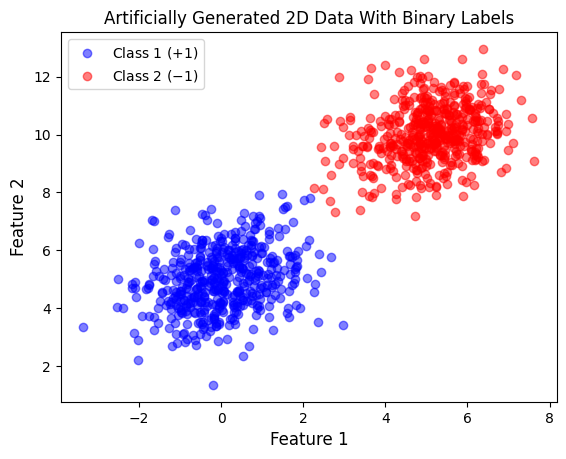

In [4]:
plt.figure()

plt.title("Artificially Generated 2D Data With Binary Labels")
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)

plt.scatter(
    features[labels == 1, 0],  # x-coordinate
    features[labels == 1, 1],  # y-coordinate
    label="Class 1 ($+1$)",
    color="blue",
    alpha=0.5,
)
plt.scatter(
    features[labels != 1, 0],  # x-coordinate
    features[labels != 1, 1],  # y-coordinate
    label="Class 2 ($-1$)",
    color="red",
    alpha=0.5,
)

plt.legend(loc="upper left")
plt.show()

In logistic regression, we use _gradient ascent_ to solve for the weight vector that _maximizes_ the (log) likelihood of observing the data. As you have learned so far, this _optimal_ weight vector defines a perpendicular hyperplane that _best_ divides the data points of the two classes.

**Equivalently, we can use gradient _descent_ to solve for the weight vector that _minimizes_ the _negative_ log likelihood - refer to Module 3 if you need a review of this derivation!**

So, let's continue walking backwards from our goal. Now that we have an artificial dataset, we need to create a logistic regression classifier. For the classifier, we will need to compute the negative log likelihood (modeled using the logistic loss function) and a function to train the minimize the negative log likelihood using gradient descent.

The logistic loss uses the sigmoid function, which you will implement first. Next, you will implement $P \left(y_i | \mathbf{x}_i \right)$ using the sigmoid function, followed by the negative log likelihood. You will use these functions in the subsequent projects.

## Part One: Sigmoid [Graded]

Use the NumPy function `np.exp()` to implement the function **`sigmoid(z)`** (i.e., $\sigma(z)$) in the cell below. Recall that $\sigma(z)$ is defined by the following formula:

$$
\sigma(z) = \frac{1}{1 + \exp(-z)}
$$

**NOTE:** The mathematical notation $\exp(u)$ is another way of expressing the natural exponential function $e^u$.

In [5]:
def sigmoid(z):
    """
    Calculates the sigmoid of z.

    Input:
        z: scalar or array of dimension n

    Output:
        scalar or array of dimension n
    """
    # YOUR CODE HERE
    sgmd = 1/ (1 + np.exp(-z))
    # END OF YOUR CODE

    return sgmd

Let's plot the sigmoid function for values around 0. The sigmoid function should *plateau* (i.e., output almost a constant value) for negative or positive values of large magnitude.

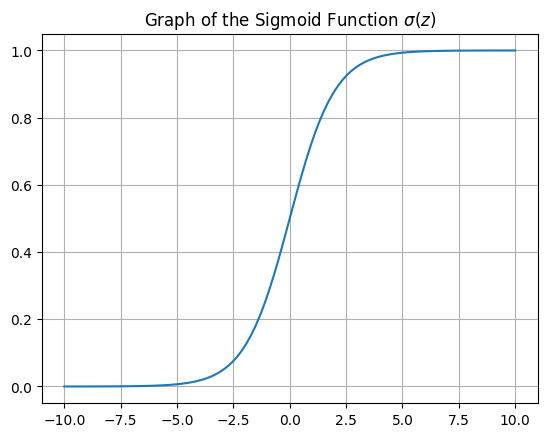

In [6]:
z = np.linspace(-10, 10, 100)
y = sigmoid(z)

plt.figure()
plt.plot(z, y)
plt.title(r"Graph of the Sigmoid Function $\sigma(z)$")
plt.grid()
plt.show()

Run the next cell to check your implementation of `sigmoid`.

In [9]:
def sigmoid_test1():
    """
    Check that your sigmoid output has the correct shape
    """
    h = np.random.rand(10)              # Input is a random 10-dimensional array
    return sigmoid(h).shape == h.shape  # Output should be a 10-dimensional array


def sigmoid_test2():
    """
    Check your sigmoid outputs against our sigmoid outputs
    """
    np.random.seed(1)          # Set a random seed for consistency
    h = np.random.rand(10)     # Input is a random 10-dimensional array
    sgmd1 = sigmoid(h)         # Compute sigmoids with your function
    sgmd2 = sigmoid_grader(h)  # Compute sigmoids with our function
    diff_sgmds = np.linalg.norm(sgmd1 - sgmd2)
    return diff_sgmds < 1e-5   # Difference should be small


def sigmoid_test3():
    """
    Another check that your sigmoid output is close to ours
    """
    np.random.seed(2)          # Set a random seed for consistency
    x = np.random.rand(1)      # Input is a random scalar
    sgmd1 = sigmoid(x)         # Compute sigmoid with your function
    sgmd2 = sigmoid_grader(x)  # Compute sigmoid with our function
    diff_sgmds = np.linalg.norm(sgmd1 - sgmd2)
    return diff_sgmds < 1e-5   # Difference should be small


def sigmoid_test4():
    """
    Check your sigmoid outputs against known sigmoid outputs
    """
    # Three inputs: very negative, very positive, and zero
    x = np.array([-1e10, 1e10, 0])  

    # Compute the output with your sigmoid function
    sgmd = sigmoid(x)

    # The first two sigmoid outputs should be very close to 0 and 1,
    # and the last sigmoid output should be exactly 0.5.
    truth = np.array([0, 1, 0.5])
    diff_sgmd_truth = np.linalg.norm(sgmd - truth)
    
    return diff_sgmd_truth < 1e-8  # Difference should be very small


runtest(sigmoid_test1, "sigmoid_test1")
runtest(sigmoid_test2, "sigmoid_test2")
runtest(sigmoid_test3, "sigmoid_test3")
runtest(sigmoid_test4, "sigmoid_test4")

Running Test: sigmoid_test1 ... ✔ Passed!
Running Test: sigmoid_test2 ... ✔ Passed!
Running Test: sigmoid_test3 ... ✔ Passed!
Running Test: sigmoid_test4 ... ✔ Passed!


/tmp/ipykernel_517/307983514.py:12: RuntimeWarning: overflow encountered in exp
  sgmd = 1/ (1 + np.exp(-z))


**NOTE:** When the `np.exp` function is called, you may receive warnings that say `RuntimeWarning: overflow encountered in exp`. These can be ignored.

Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (sigmoid_test1)

In [ ]:
# Auto-graded test cell worth one point (sigmoid_test2)

In [ ]:
# Auto-graded test cell worth one point (sigmoid_test3)

In [ ]:
# Auto-graded test cell worth one point (sigmoid_test4)

## Part Two: Implement `y_pred` [Graded]

Implement the function **`y_pred(X, w, b=0)`** that computes $P( y_i = 1 | \mathbf{x}_i ; \mathbf{w}, b)$ for each row-vector $\mathbf{x}_i$ in the matrix `X`.

Recall that the probability of $\mathbf{x}_i$ having label $y_i$ is calculated using the sigmoid function:

$$
P( y_i | \mathbf{x}_i; \mathbf{w}, b ) 
= \sigma \left( y_i \left( \mathbf{w}^\top \mathbf{x}_i + b \right) \right)
$$

Since `y_pred` calculates the probability of the positive label $+1$, the sigmoid $\sigma \left( y_i \left( \mathbf{w}^\top \mathbf{x}_i + b \right) \right)$ simplifies to $\sigma \left( \mathbf{w}^\top \mathbf{x}_i + b \right)$, which is what you must output. When writing your code, keep in mind that Python performs component-wise operations on vectors and the result of the matrix product `X @ w` is a vector whose components are $\mathbf{w}^\top\mathbf{x}_i$, i.e., $[\mathbf{X}\mathbf{w}]_i = \mathbf{x}_i^\top \mathbf{w} = \mathbf{w}^\top\mathbf{x}_i$ for all $i$.

In [13]:
def y_pred(X, w, b=0):
    """
    Calculates the probability of the positive class.

    Input:
        X: data matrix of shape nxd
        w: d-dimensional vector
        b: scalar (optional, default is 0)

    Output:
        n-dimensional vector
    """
    # YOUR CODE HERE
    prob = sigmoid(X @ w + b)
    # END OF YOUR CODE

    return prob

Let's do a sanity check for the `y_pred` function using a small test set. You can do a quick check:
> For a data point $i$, determine whether $P(y_i = 1 | \mathbf{x}_i; \mathbf{w}, b)$ (i.e., `y_pred[i]`) is close to 1 or 0 when $\mathbf{w}^\top \mathbf{x}_i + b$ is significantly greater than 0 or significantly less than 0, respectively.

Why does the check work? Recall the output of the sigmoid function for positive and negative values. When the input to sigmoid is large and positive, the output probability is close to 1. And when the input is large and negative, the probability is close to 0.

In [14]:
n, d = 5, 3
X = np.random.randint(0, 3, (n, d))  # Contains multiple observations as rows
w = np.random.randint(-3, 3, d)      # This will be our trained vector of coefficients
b = 1                                # This will be our trained offset (or bias) scalar
pY = y_pred(X, w, b).round(2)
print(f"X = \n{X}")
print(f"w = {w}, b = {b}")
print(f"Vector of probabilities of class +1 (conditional on x and w) = {pY}")
print(f"Vector of probabilities of class -1 (conditional on x and w) = {1-pY}")

X = 
[[2 2 1]
 [2 0 1]
 [0 0 2]
 [2 1 2]
 [0 0 2]]
w = [ 1 -1  1], b = 1
Vector of probabilities of class +1 (conditional on x and w) = [0.88 0.98 0.95 0.98 0.95]
Vector of probabilities of class -1 (conditional on x and w) = [0.12 0.02 0.05 0.02 0.05]


Run the next cell to check your implementation of `y_pred`.

In [15]:
def y_pred_test1():
    """
    Check that your y_pred output has the correct shape
    """
    # Generate n random vectors with d dimensions
    n = 20
    d = 5
    X = np.random.rand(n, d)

    # Define a random weight vector
    w = np.random.rand(d)

    # Compute probabilities P(y=1|X;w,b=0) using your y_pred function
    probs = y_pred(X, w, 0)

    # Check if the output of y_pred has the correct shape
    return probs.shape == (n,)


def y_pred_test2():
    """
    Check that your y_pred output has the correct range
    """
    # Generate n random vectors with d dimensions
    n = 20
    d = 5
    X = np.random.rand(n, d)

    # Define a random weight vector
    w = np.random.rand(d)

    # Compute probabilities P(y=1|X;w,b=0) using your y_pred function
    probs = y_pred(X, w, 0)

    # Check if all outputs are >=0 and <=1
    return all(probs >= 0) and all(probs <= 1)


def y_pred_test3():
    """
    Check that your y_pred outputs sum to one
    """
    # Generate n random vectors with d dimensions
    n = 20
    d = 5
    X = np.random.rand(n, d)

    # Define a random weight vector
    w = np.random.rand(d)

    # Compute probabilities P(y=1|X;w,b=0) using your y_pred function
    probs1 = y_pred(X, w, 0)

    # Compute probabilities P(y=-1|X;w,b=0) = P(y=1|X;-w,b=0) using your y_pred function
    probs2 = y_pred(X, -w, 0)

    # Check if P(y=1|X;w,b=0) + P(y=-1|X;w,b=0) = 1
    return np.linalg.norm(probs1 + probs2 - 1) < 1e-08


def y_pred_test4():
    """
    Check that your y_pred function matches true values
    """
    # Set a random seed for consistency
    np.random.seed(1)
    
    # Define random input
    X = np.random.rand(25, 4)

    # Weight vector with all weight on the first feature
    w = np.array([1, 0, 0, 0])

    # Compute P(y=1|X;w,b=0)
    prob = y_pred(X, w, 0)

    # Ground truth should be the sigmoid of the first feature
    truth = sigmoid(X[:, 0])

    # Check if predictions match the ground truth
    return np.linalg.norm(prob - truth) < 1e-08


def y_pred_test5():
    """
    Another check that your y_pred function matches true values
    """
    # Define 3 inputs (2D)
    X = np.array(
        [
            [0.61793598, 0.09367891],
            [0.79447745, 0.98605996],
            [0.53679997, 0.4253885],
        ]
    )
    
    # Define weight vector
    w = np.array([0.9822789, 0.16017851])

    # Compute probabilities P(y=1|X;w,b=3)
    prob = y_pred(X, w, 3)

    # This is the ground truth
    truth = np.array([0.97396645, 0.98089179, 0.97328431])

    # Check if predictions match the ground truth
    return np.linalg.norm(prob - truth) < 1e-08


runtest(y_pred_test1, "y_pred_test1")
runtest(y_pred_test2, "y_pred_test2")
runtest(y_pred_test3, "y_pred_test3")
runtest(y_pred_test4, "y_pred_test4")
runtest(y_pred_test5, "y_pred_test5")

Running Test: y_pred_test1 ... ✔ Passed!
Running Test: y_pred_test2 ... ✔ Passed!
Running Test: y_pred_test3 ... ✔ Passed!
Running Test: y_pred_test4 ... ✔ Passed!
Running Test: y_pred_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (y_pred_test1)

In [ ]:
# Auto-graded test cell worth one point (y_pred_test2)

In [ ]:
# Auto-graded test cell worth one point (y_pred_test3)

In [ ]:
# Auto-graded test cell worth one point (y_pred_test4)

In [ ]:
# Auto-graded test cell worth one point (y_pred_test5)

## Part Three: Implement `log_loss` [Graded]

Now you will compute the negative log-likelihood (`nll`) in the function **`log_loss(X, y, w, b=0)`**. You are given the label vector `y` and the data matrix `X` with `n` data points as row vectors. The negative log likelihood (`nll` is in the body of `log_loss`) is defined mathematically as follows:

$$
\begin{aligned}
\mathcal{L}(\mathbf{w})
&= -\log \left( P(\mathbf{y} \vert \mathbf{X}; \mathbf{w}, b) \right) \\[5pt]
&= -\log \prod_{i=1}^n P \left(y_i | \mathbf{x}_i; \mathbf{w}, b \right) \\[5pt]
&= -\sum_{i=1}^n \log \left( P\left(y_i | \mathbf{x}_i; \mathbf{w}, b \right) \right) \\[5pt]
&= -\sum_{i=1}^n \log \left( \sigma \left( y_i \left(\mathbf{w}^\top \mathbf{x}_i + b \right) \right) \right)
\end{aligned}
$$

Since $\sigma(z) = \dfrac{1}{1 + \exp(-z)}$, the negative log-likelihood can be expressed as

$$
\mathcal{L}(\mathbf{w})
= \sum_{i=1}^n \log \left( 1 + \exp\left( - y_i \left(\mathbf{w}^\top \mathbf{x}_i + b \right) \right) \right)
$$

You only computed the probability of a positive label in `y_pred`. Now you will account for the actual value of the labels $y_i$. You can use your implementation of `y_pred` for `log_loss` or reimplement to account for the $y$ &mdash; the latter yields cleaner code. When writing your code, keep in mind that Python performs component-wise operations on vectors and the result of the matrix product `X @ w` is a vector whose components are $\mathbf{w}^\top\mathbf{x}_i$, i.e., $[\mathbf{X}\mathbf{w}]_i = \mathbf{x}_i^\top \mathbf{w} = \mathbf{w}^\top\mathbf{x}_i$ for all $i$.

In [16]:
def log_loss(X, y, w, b=0):
    """
    Calculates the negative log-likelihood for dataset (X, y)
    using the weight vector w and bias b.

    Input:
        X: data matrix of shape nxd
        y: n-dimensional vector of labels (+1 or -1)
        w: d-dimensional vector
        b: scalar (optional, default is 0)

    Output:
        scalar
    """
    assert np.sum(np.abs(y)) == len(y)  # Check all labels are either +1 or -1

    # YOUR CODE HERE
    results = X @ w + b
    losses = np.log(1 + np.exp(-(y * results)))
    nll = np.sum(losses)
    # END OF YOUR CODE

    return nll

Run the next cell to check your implementation of `log_loss`.

In [17]:
def log_loss_test1():
    """
    Check that the output of your log_loss function is a scalar
    """
    X = np.random.rand(25, 5)  # Generate n random vectors with d dimensions
    w = np.random.rand(5)      # Define a random weight vector
    b = np.random.rand(1)      # Define a random bias term
    y = np.ones(25)            # Set all labels to +1 (ground truth)
    ll = log_loss(X, y, w, b)  # Compute log loss between y and y_pred
    return np.isscalar(ll)


def log_loss_test2():
    """
    Check that your log_loss function yields the correct output.
    Note: If the labels are all one, the output of your log_loss
    function should be the (negative) sum of log of y_pred.
    """
    X = np.random.rand(25, 5)   # Generate n random vectors with d dimensions
    w = np.random.rand(5)       # Define a random weight vector
    b = np.random.rand(1)       # Define a random bias term
    y = np.ones(25)             # Set all labels to +1 (ground truth)
    ll1 = log_loss(X, y, w, b)  # Compute log loss between y and y_pred
    ll2 = -np.sum(np.log(y_pred(X, w, b)))    # Negative sum of log of y_pred
    return np.linalg.norm(ll1 - ll2) < 1e-05  # Difference should be small


def log_loss_test3():
    """
    Another check that your log_loss function yields the correct output.
    Note: If the labels are all negative one, the output of your log_loss
    function should be the (negative) sum of log of 1-y_pred.
    """
    X = np.random.rand(25, 5)   # Generate n random vectors with d dimensions
    w = np.random.rand(5)       # Define a random weight vector
    b = np.random.rand(1)       # Define a random bias term
    y = -np.ones(25)            # Set all labels to -1 (ground truth)
    ll1 = log_loss(X, y, w, b)  # Compute log loss between y and y_pred
    ll2 = -np.sum(np.log(1 - y_pred(X, w, b)))  # Negative sum of log of 1-y_pred
    return np.linalg.norm(ll1 - ll2) < 1e-05    # Difference should be small


def log_loss_test4():
    """
    Another check that your log_loss function yields the correct output
    """
    X = np.random.rand(20, 5)               # Generate n random vectors with d dimensions
    w = np.array([0, 0, 0, 0, 0])           # Define a weight vector with all zeros
    y = (np.random.rand(20) > 0.5) * 2 - 1  # Define n random labels +1 or -1 (ground truth)
    ll = log_loss(X, y, w, 0)               # Compute log loss between y and y_pred
    
    # The log-likelihood for each of the 20 examples should be exactly 0.5
    return np.linalg.norm(ll + 20 * np.log(0.5)) < 1e-08


def log_loss_test5():
    """
    Check the output of your log_loss against the output of ours
    """
    np.random.seed(1)                         # Set a random seed for consistency
    X = np.random.rand(500, 15)               # Generate n random vectors with d dimensions
    w = np.random.rand(15)                    # Define a random weight vector
    b = np.random.rand(1)                     # Define a random bias term
    y = (np.random.rand(500) > 0.5) * 2 - 1   # Define n random labels +1 or -1 (ground truth)
    ll1 = log_loss(X, y, w, b)                # Compute your log loss between y and y_pred
    ll2 = log_loss_grader(X, y, w, b)         # Compute our log loss between y and y_pred
    return np.linalg.norm(ll1 - ll2) < 1e-05  # Difference should be small


runtest(log_loss_test1, "log_loss_test1")
runtest(log_loss_test2, "log_loss_test2")
runtest(log_loss_test3, "log_loss_test3")
runtest(log_loss_test4, "log_loss_test4")
runtest(log_loss_test5, "log_loss_test5")

Running Test: log_loss_test1 ... ✔ Passed!
Running Test: log_loss_test2 ... ✔ Passed!
Running Test: log_loss_test3 ... ✔ Passed!
Running Test: log_loss_test4 ... ✔ Passed!
Running Test: log_loss_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (log_loss_test1)

In [ ]:
# Auto-graded test cell worth one point (log_loss_test2)

In [ ]:
# Auto-graded test cell worth one point (log_loss_test3)

In [ ]:
# Auto-graded test cell worth one point (log_loss_test4)

In [ ]:
# Auto-graded test cell worth one point (log_loss_test5)